Number of readings=100, mean=29.182999999999996, minimum=10.26, maximum=49.9, standard_deviation=11.740780510681562, number of readings above threshold=22
Readings above threshold:
Sample 7: 45.69
Sample 19: 42.38
Sample 21: 42.23
Sample 25: 48.29
Sample 29: 43.9
Sample 31: 42.29
Sample 34: 48.92
Sample 37: 43.18
Sample 39: 44.47
Sample 54: 47.47
Sample 61: 49.58
Sample 65: 43.71
Sample 66: 41.04
Sample 72: 47.72
Sample 73: 45.05
Sample 77: 46.58
Sample 84: 45.91
Sample 87: 49.9
Sample 93: 41.68
Sample 97: 49.84
Sample 99: 48.84
Sample 100: 44.43


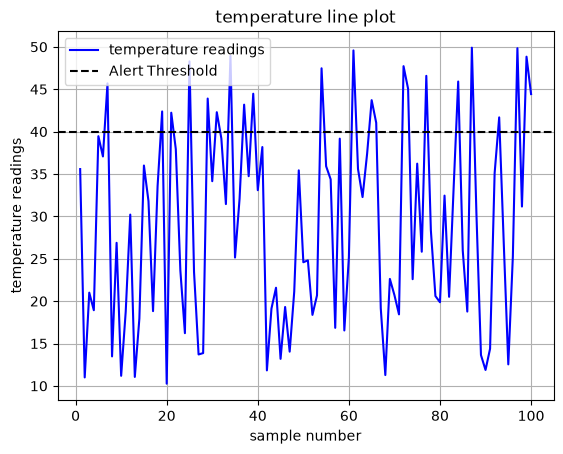

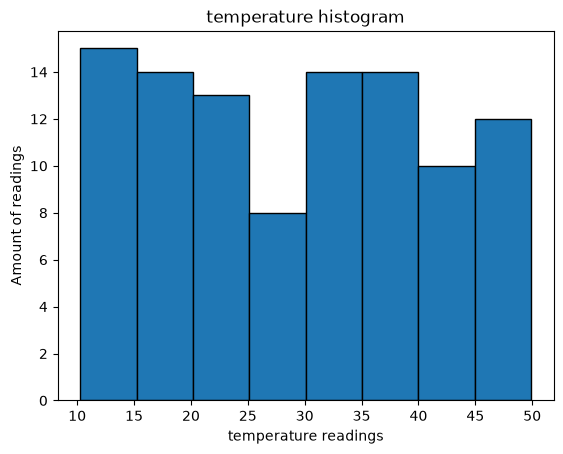

In [ ]:
import random
import csv
import numpy as np
import matplotlib.pyplot as plt


def get_user_input():
    """
    get user input for sensor type, number of readings, min and max values, and alert threshold. and check if the inputs are valid.

    Returns:
    type of sensor, number of readings, min value, max value, alert threshold if inputs are valid. Otherwise, returns None.
    """
    Sensor_type = input("Enter the sensor type (e.g., temperature, humidity, pressure): ")
    Number_of_readings = int(input("Enter the number of readings you want to input: "))
    Min_value = float(input("Enter the minimum value for the readings: "))
    Max_value = float(input("Enter the maximum value for the readings: "))
    Alert_threshold = float(input("Enter the alert threshold value: "))
    
    if Number_of_readings <= 0:
        print("Number of readings must be a positive number.")
        return None
    elif Min_value >= Max_value:
        print("Minimum value must be less than maximum value.")
        return None
    elif Alert_threshold < Min_value or Alert_threshold > Max_value:
        print("Alert threshold must be within the range of minimum and maximum values.")
        return None
    else:
        return Sensor_type, Number_of_readings, Min_value, Max_value, Alert_threshold


def generate_readings(Number_of_readings, Min_value, Max_value):
    """
    Generate a list of random readings within the specified range.

    Returns:
    A list of the readings.
    """
    random.seed(42)
    Readings =[round(random.uniform(Min_value, Max_value), 2) for _ in range(Number_of_readings)]
    return Readings

def save_readings(filename, readings, Sensor_type, Min_value, Max_value, Alert_threshold):
    """
    Saves a .csv file with all readings + minimum, maximum, alert threshold and which type of sensor it is
    """
    with open(filename, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)

        writer.writerow([f"Sensor Type: {Sensor_type}"])
        writer.writerow(["sample", "readings", "min", "max", "alert_threshold"])

        for sample_number, angle in enumerate(readings, start=1):
            if sample_number == 1:
                writer.writerow([sample_number, angle, Min_value, Max_value, Alert_threshold])
            else:
                writer.writerow([sample_number, angle, None, None, None])
        

def load_readings(filename):
    """
    Load data from a specified file

    returns:
    A list with the readings, the type of sensor and the Alert threshold
    """
    readings = []

    with open(filename, "r", newline="", encoding="utf-8") as file:
        first_line = next(file).strip()
        sensor_type = first_line.replace("Sensor Type: ", "")

        reader = csv.DictReader(file)

        Alert_threshold = float(next(reader)["alert_threshold"])
        readings.append(float(next(reader)["readings"]))
        for row in reader:
            readings.append(float(row["readings"]))

    return readings, Alert_threshold, sensor_type

def calculate_statistics(readings, Alert_threshold):
    """
    Calculate the number of readings, the mean, the minimum, the maximum, the standard devitation and the amount and which readings are above the alert threshold
    
    returns:
    all the calulated statistics
    """
    number_of_readings = len(readings)
    mean = np.mean(readings)
    min = np.min(readings)
    max = np.max(readings)
    std_dev = np.std(readings)
    amount_above_threshold = sum(1 for reading in readings if reading > Alert_threshold)
    above_threshold = [(sample_number, reading) for sample_number, reading in enumerate(readings, start=1) if reading > Alert_threshold]
    print(f"Number of readings={number_of_readings}, mean={mean}, minimum={min}, maximum={max}, standard_deviation={std_dev}, number of readings above threshold={amount_above_threshold}")
    print("Readings above threshold:")
    for sample_number, reading in above_threshold:
        print(f"Sample {sample_number}: {reading}")
    return number_of_readings, mean, min, max, std_dev, amount_above_threshold

def plot_readings(readings, sample_number, Sensor_type, Alert_threshold):
    """
    Makes a line plot of the readings and saves it as a .png file
    """
    fig, ax = plt.subplots()

    ax.plot(sample_number, readings, label=f'{Sensor_type} readings', color="blue")

    plt.axhline(Alert_threshold, linestyle="--", label="Alert Threshold", color="black")

    ax.set(xlabel='sample number', ylabel=f'{Sensor_type} readings',
       title=f'{Sensor_type} line plot')
    ax.grid()
    plt.legend()
    fig.savefig("Line_Plot.png")
    
    plt.show()

def plot_histogram(readings, Sensor_type):
    """
    Makes a histogram of the readings and saves it as a .png file
    """
    n_bins = 'auto'
    
    fig, axs = plt.subplots()
    axs.hist(readings, bins=n_bins, edgecolor="black")
    axs.set(xlabel=f'{Sensor_type} readings', ylabel='Amount of readings',
           title=f'{Sensor_type} histogram')
    fig.savefig("Histogram.png")
    plt.show()
  

def main():
    """
    Main function to run the program.It asks the user if they want to load readings from a file or generate new readings. It then calculates statistics and plots the readings and histogram.

    """
    if input("Do you want to load readings from a file? (yes/no): ").strip().lower() == "yes":
        filename = input("Enter the filename to load readings from: ")
        readings, Alert_threshold, Sensor_type = load_readings(filename)

    else:
        values = get_user_input()
        Sensor_type, Number_of_readings, Min_value, Max_value, Alert_threshold = values
        readings = generate_readings(Number_of_readings, Min_value, Max_value)
        save_readings("readings.csv", readings, Sensor_type, Min_value, Max_value, Alert_threshold)

    calculate_statistics(readings, Alert_threshold)
    sample_number = list(range(1, len(readings) + 1))
    plot_readings(readings,sample_number, Sensor_type, Alert_threshold)
    plot_histogram(readings, Sensor_type)

if __name__ == "__main__":
    main()
